# Importi

In [18]:
import sympy as sp
import matplotlib.pyplot as plt
import numpy as np

a = 2.0
b = 2.5

# Funkcije

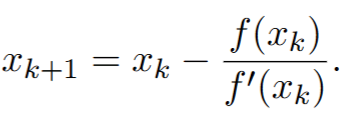

In [32]:
def bisekcija(f:sp.Expr, a, b, tol = 1e-5, max_iter = 200):
    st_iteracij = 0
    while st_iteracij < max_iter:
        c = (a + b)/2.0
        fa = f.subs(x,a)
        fc = f.subs(x,c)
        fb = f.subs(x,b)
        
        if fa*fc > 0:
            a = c
        elif fb*fc > 0:
            b = c
        else:
            return None
        eps = np.abs(fc)
        st_iteracij += 1
        res = {"x*": c, "st_iteracij": st_iteracij}
        if eps < tol:
            return res
    return res

def sekantna_metoda(f:sp.Expr, x0, x1, tol = 1e-5, max_iter = 200):
    st_iteracij = 0
    while st_iteracij < max_iter:
        f0 = f.subs(x,x0)
        f1 = f.subs(x,x1)
        x2 = x1 - f1*(x1 - x0)/(f1 - f0)
        f2 = f.subs(x,x2)
        
        if np.abs(f2) < tol:
            return {"x*": x2, "st_iteracij":st_iteracij}
        
        x0 = x1
        x1 = x2
        st_iteracij += 1
    return {"x*": x2, "st_iteracij":st_iteracij}

def newton_metoda(f:sp.Expr, x0, tol = 1e-5, max_iter = 200):
    st_iteracij = 0
    df = sp.diff(f, x)
    while st_iteracij < max_iter:
        f0 = f.subs(x,x0)
        df0 = df.subs(x,x0)
        x1 = x0 - f0/df0
        
        f1 = f.subs(x,x1)
        
        if np.abs(f1) < tol:
            return {"x*": x1, "st_iteracij":st_iteracij}
        
        x0 = x1
        
        st_iteracij += 1
    return {"x*": x1, "st_iteracij":st_iteracij}

nabor_metod = {"Bisekcija": bisekcija,
               "Sekantna": sekantna_metoda,
               "Newton": newton_metoda}

# Testiranje

In [28]:
res = newton_metoda(df_x,0.8)
res-np.pi/3

1.16563543262060e-8

# Naloga 1

In [17]:
x = sp.Symbol('x')
f_x = x - 2*sp.sin(x) - 0.5
df_x = sp.diff(f_x, x)
display(df_x)

fa = f_x.subs(x, a)
fb = f_x.subs(x, b)

print(f"f(a) = {fa}")
print(f"f(b) = {fb}")

dfa = df_x.subs(x, a)
dfb = df_x.subs(x, b)

print(f"f'(a) = {dfa}")
print(f"f'(b) = {dfb}")

sol = sp.solve(df_x,x)
sol

1 - 2*cos(x)

f(a) = -0.318594853651363
f(b) = 0.803055711792087
f'(a) = 1.83229367309428
f'(b) = 2.60228723109387


[pi/3, 5*pi/3]

# Naloga 2

In [34]:
for metoda in ['Bisekcija','Sekantna','Newton']:
    for tol in [1e-6,1e-12]:
        if metoda=="Newton":
            r = nabor_metod[metoda](f_x, x0=a, tol = tol)
        else:
            r = nabor_metod[metoda](f_x, a, b, tol = tol)
        print(metoda, tol, r)

Bisekcija 1e-06 {'x*': 2.1613101959228516, 'st_iteracij': 18}
Bisekcija 1e-12 {'x*': 2.1613097934650796, 'st_iteracij': 39}
Sekantna 1e-06 {'x*': 2.16130977989351, 'st_iteracij': 3}
Sekantna 1e-12 {'x*': 2.16130979346536, 'st_iteracij': 4}
Newton 1e-06 {'x*': 2.16130979493366, 'st_iteracij': 2}
Newton 1e-12 {'x*': 2.16130979346545, 'st_iteracij': 3}
